In [1]:
import re

import pandas as pd

DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
UNIPROT_DATA_PATH = DATA_PATH_BASE + '/uniprot_data/'

In [2]:
substr_to_search = 0

In [3]:
seq = 'ELRHSKQYENVNLI'
substr = seq[0:11]

In [4]:
import numpy as np
np.array(list(substr))

array(['E', 'L', 'R', 'H', 'S', 'K', 'Q', 'Y', 'E', 'N', 'V'], dtype='<U1')

In [5]:
target_seq = r'.P...T..C.K'

In [11]:
from Bio.SeqIO.FastaIO import SimpleFastaParser
from tqdm import tqdm
uniprot_file = f'{UNIPROT_DATA_PATH}uniprot_sprot.fasta'

def read_uniprot_file_to_dict_simple(file_path):
    result_dict = dict()
    results = list()
    ids = list()
    records= list()
    with open(file_path) as handle:
        for record in tqdm(SimpleFastaParser(handle)):
            # iterate over sequence
            protein_seq = record[1]
            res = re.search(target_seq, protein_seq)
            if res:
                results.append(res)
                uniprot_id = record[0].split('|',2)[1]
                ids.append(uniprot_id)
                records.append(record[0])
    return results,  ids, records
result = read_uniprot_file_to_dict_simple(uniprot_file)

564277it [00:10, 53490.32it/s]


In [12]:
matches = result[0]
ids = result[1]
records = result[2]

In [13]:
ids

['Q7T2I3',
 'Q86UQ4',
 'Q5SSE9',
 'Q07586',
 'Q8IZF6',
 'B6KAM0',
 'P0CQ11',
 'P0CQ10',
 'Q9YPS6',
 'Q0VCW3',
 'Q502P7',
 'Q8N9N5',
 'Q8VBU8',
 'P9WID8',
 'P9WID9',
 'Q83CY8',
 'P9WIE0',
 'P9WIE1',
 'Q9HF75',
 'Q7F8R0',
 'Q5PP65',
 'P48284',
 'O75808',
 'Q8TCT0',
 'J9VWH9',
 'P51641',
 'B7GLS9',
 'Q923L3',
 'O21224',
 'O21163',
 'O21166',
 'O21167',
 'O79219',
 'O79220',
 'O79221',
 'O21205',
 'B9JI94',
 'B9K2I7',
 'B2SDA2',
 'Q2YIL0',
 'Q579E2',
 'A9MCK4',
 'C0RM68',
 'Q8YD04',
 'A5VVJ0',
 'A9WVT6',
 'Q8FVC0',
 'A6WYV7',
 'B4RBL4',
 'Q9RAE6',
 'A6UB96',
 'A5V4F9',
 'Q9ZMM0',
 'P0CAP0',
 'I1T3C7',
 'Q8IV53',
 'A0B738',
 'Q65956',
 'Q96687',
 'O83642',
 'B2S3M4',
 'Q09477',
 'Q185R8',
 'Q0TPQ9',
 'Q8XJR1',
 'Q0SSC6',
 'Q7VC14',
 'P0CN35',
 'P0CN34',
 'Q9QBZ0',
 'Q89607',
 'P17281',
 'P05885',
 'P08810',
 'P05884',
 'P11267',
 'P19503',
 'Q4WM32',
 'Q5BFX0',
 'A6NHR8',
 'P35731',
 'Q9STQ0',
 'Q4FVJ7',
 'Q1QEM5',
 'Q8BPY9',
 'P08191',
 'P08640',
 'Q54VW7',
 'Q8MLZ5',
 'Q07928',
 'O70237',

In [14]:
new_matches = [match.group(0) for match in matches]
starts = [match.start() for match in matches]
ends = [match.end() for match in matches]

In [16]:
df = pd.DataFrame({"protein_id": ids, "match":new_matches, "start": starts, "end": ends, "record_id": records})

In [21]:
[match.start() for match in matches]

[35, 35, 40, 40, 96, 92, 91, 87, 92, 90, 80]

In [3]:
with open('tomas_result.xml') as f:
    text = f.readlines()

In [5]:
input_text = ''.join(text)

In [6]:
import xmltodict
xml_result = xmltodict.parse(input_text)


In [7]:
xml_result.keys()

dict_keys(['BlastOutput'])

In [16]:
hits = xml_result['BlastOutput']['BlastOutput_iterations']['Iteration']['Iteration_hits']['Hit']

In [17]:
len(hits)

44

In [19]:
for hit in hits:
    print(hit['Hit_hsps']['Hsp']['Hsp_hseq'])

VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSQ
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
VPGAFTPGCSK
IPGAFTPGCSK
VPGAFTPGCSK


In [11]:
import pandas as pd

In [12]:
df = pd.read_csv('C:\Projects\Tomas project\whole_table.csv', sep=';')

In [13]:
df

,Unnamed: 0,protein_id,match,start,end,record_id
0,0,HJD49578.1,YPRANTPGCTK,45,56,HJD49578.1 thioredoxin-dependent thiol peroxid...
1,1,KAI4462845.1,VPGAFTPGCSK,68,79,KAI4462845.1 peroxiredoxin [Holotrichia oblita]
2,2,WP_250183260.1,YPAAMTPGCTK,37,48,WP_250183260.1 thioredoxin-dependent thiol per...
3,3,WP_030144681.1,YPRAMTPGCTK,38,49,WP_030144681.1 thioredoxin-dependent thiol per...
4,4,WP_069928604.1,YPAALTPGCTK,38,49,WP_069928604.1 thioredoxin-dependent thiol per...
...,...,...,...,...,...,...
9706,9706,XP_027842703.1,VPGAFTPGCSK,73,84,"XP_027842703.1 peroxiredoxin-5, mitochondrial ..."
9707,9707,MBL6620715.1,YPKADTPGCTK,36,47,MBL6620715.1 thioredoxin-dependent thiol perox...
9708,9708,MQA61686.1,YPKAATPGCTK,39,50,MQA61686.1 thioredoxin-dependent thiol peroxid...
9709,9709,WP_046259001.1,YPAALTPGCTK,38,49,WP_046259001.1 thioredoxin-dependent thiol per...


In [14]:
import re
re.search(r'\[.*\]', df['record_id'][0])

<re.Match object; span=(50, 92), match='[Candidatus Corynebacterium intestinavium]'>

In [15]:
df['record_id'][1000]

'MDB4599252.1 peroxiredoxin [Alphaproteobacteria bacterium]\x01MDC1117815.1 peroxiredoxin [Alphaproteobacteria bacterium]'

In [16]:
organisms = [re.search(r'\[(([^\[\]])*)\]', record).group(1) for record in df['record_id'] ]

In [17]:
pattern = re.compile(r'(.*)( sp..*)')

In [18]:
organism_general = [re.sub(pattern, r'\1', organism) for organism in organisms]

In [19]:
df['organism'] = organisms
df['organism_general'] = organism_general

In [20]:
df

,Unnamed: 0,protein_id,match,start,end,record_id,organism,organism_general
0,0,HJD49578.1,YPRANTPGCTK,45,56,HJD49578.1 thioredoxin-dependent thiol peroxid...,Candidatus Corynebacterium intestinavium,Candidatus Corynebacterium intestinavium
1,1,KAI4462845.1,VPGAFTPGCSK,68,79,KAI4462845.1 peroxiredoxin [Holotrichia oblita],Holotrichia oblita,Holotrichia oblita
2,2,WP_250183260.1,YPAAMTPGCTK,37,48,WP_250183260.1 thioredoxin-dependent thiol per...,Aeromicrobium fastidiosum,Aeromicrobium fastidiosum
3,3,WP_030144681.1,YPRAMTPGCTK,38,49,WP_030144681.1 thioredoxin-dependent thiol per...,Glycomyces sp. NRRL B-16210,Glycomyces
4,4,WP_069928604.1,YPAALTPGCTK,38,49,WP_069928604.1 thioredoxin-dependent thiol per...,Streptomyces agglomeratus,Streptomyces agglomeratus
...,...,...,...,...,...,...,...,...
9706,9706,XP_027842703.1,VPGAFTPGCSK,73,84,"XP_027842703.1 peroxiredoxin-5, mitochondrial ...",Aphis gossypii,Aphis gossypii
9707,9707,MBL6620715.1,YPKADTPGCTK,36,47,MBL6620715.1 thioredoxin-dependent thiol perox...,Ilumatobacteraceae bacterium,Ilumatobacteraceae bacterium
9708,9708,MQA61686.1,YPKAATPGCTK,39,50,MQA61686.1 thioredoxin-dependent thiol peroxid...,Actinophytocola sp.,Actinophytocola
9709,9709,WP_046259001.1,YPAALTPGCTK,38,49,WP_046259001.1 thioredoxin-dependent thiol per...,Streptomyces sp. WM6386,Streptomyces


In [21]:
df[df.organism_general == 'Mycobacterium sp.']

,Unnamed: 0,protein_id,match,start,end,record_id,organism,organism_general


In [22]:
df.organism_general.value_counts()

Streptomyces                 792
Mycobacterium                324
Arthrobacter                 150
unclassified Streptomyces    124
Rhodococcus                  117
                            ... 
Umbelopsis ramanniana AG       1
Desertimonas                   1
Penicillium verrucosum         1
Denticeps clupeoides           1
Nocardia ninae                 1
Name: organism_general, Length: 4266, dtype: int64

In [23]:
import seaborn as sns

In [24]:
df.groupby('organism_general').count()

,Unnamed: 0,protein_id,match,start,end,record_id,organism
organism_general,,,,,,,
Aaosphaeria arxii CBS 175.79,1,1,1,1,1,1,1
Abscondita terminalis,2,2,2,2,2,2,2
Absidia glauca,1,1,1,1,1,1,1
Absidia repens,1,1,1,1,1,1,1
Acanthamoeba castellanii str. Neff,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...
uncultured Rhodococcus,1,1,1,1,1,1,1
uncultured Rhodopila,3,3,3,3,3,3,3
uncultured Rothia,8,8,8,8,8,8,8


In [25]:
df[df.organism_general == 'Mus musculus']

,Unnamed: 0,protein_id,match,start,end,record_id,organism,organism_general
1921,1921,NP_001345373.1,VPGAFTPGCSK,87,98,"NP_001345373.1 peroxiredoxin-5, mitochondrial ...",Mus musculus,Mus musculus
3626,3626,BAE22835.1,VPGAFTPGCSK,76,87,"BAE22835.1 unnamed protein product, partial [M...",Mus musculus,Mus musculus
5040,5040,BAB26548.1,VPGAFTPGCYK,88,99,BAB26548.1 unnamed protein product [Mus musculus],Mus musculus,Mus musculus
7169,7169,NP_036151.1,VPGAFTPGCSK,87,98,"NP_036151.1 peroxiredoxin-5, mitochondrial iso...",Mus musculus,Mus musculus
7417,7417,BAE31390.1,VPGAFTPGCSK,85,96,"BAE31390.1 unnamed protein product, partial [M...",Mus musculus,Mus musculus
8970,8970,AAF27532.1,VPGAFTPGCSK,39,50,AAF27532.1 peroxisomal membrane protein 20 [Mu...,Mus musculus,Mus musculus
9291,9291,EDL33256.1,VPGAFTPGCSK,87,98,"EDL33256.1 peroxiredoxin 5, isoform CRA_a [Mus...",Mus musculus,Mus musculus


In [26]:
count_df = df.groupby('organism_general')['match'].count()

In [27]:
count_df

organism_general
Aaosphaeria arxii CBS 175.79          1
Abscondita terminalis                 2
Absidia glauca                        1
Absidia repens                        1
Acanthamoeba castellanii str. Neff    1
                                     ..
uncultured Rhodococcus                1
uncultured Rhodopila                  3
uncultured Rothia                     8
uncultured Streptomyces               2
uncultured Williamsia                 1
Name: match, Length: 4266, dtype: int64

In [28]:
count_df

organism_general
Aaosphaeria arxii CBS 175.79          1
Abscondita terminalis                 2
Absidia glauca                        1
Absidia repens                        1
Acanthamoeba castellanii str. Neff    1
                                     ..
uncultured Rhodococcus                1
uncultured Rhodopila                  3
uncultured Rothia                     8
uncultured Streptomyces               2
uncultured Williamsia                 1
Name: match, Length: 4266, dtype: int64

## Try to cluster blast results

In [426]:
from Bio.SeqIO.FastaIO import SimpleFastaParser
from tqdm import tqdm
DATA_FOLDER = 'C:\\Projects\\Tomas project\\blasting\\final_specific_pattern'

In [427]:
fasta_file = DATA_FOLDER + '\\TPxC_w3_e100_gaps.aln'

In [428]:
def read_fata_file(file_path):
    ids = list()
    seqs= list()
    with open(file_path) as handle:
        for record in tqdm(SimpleFastaParser(handle)):
            # iterate over sequence
            cur_id = record[0]
           # print(record[1])
            cur_seq = record[1]
            ids.append(cur_id)
            seqs.append(cur_seq)

    return  ids, seqs


In [429]:
ids, seqs = read_fata_file(fasta_file)

175it [00:00, 13816.27it/s]


In [430]:
df = pd.DataFrame({"id": ids, "seq":seqs})

In [431]:
df.seq.str.len()

0      10055
1      10055
2      10055
3      10055
4      10055
       ...  
170    10055
171    10055
172    10055
173    10055
174    10055
Name: seq, Length: 175, dtype: int64

In [432]:
example = seqs[0]

In [433]:
df

,id,seq
0,sp|P30044.4| [completeness=complete] [organis...,----------------------------------------------...
1,sp|Q9GLW7.1| [completeness=complete] [organis...,----------------------------------------------...
2,sp|Q9GLW9.1| [completeness=complete] [organis...,----------------------------------------------...
3,sp|P99029.2| [completeness=complete] [organis...,----------------------------------------------...
4,sp|Q9R063.1| [completeness=complete] [organis...,----------------------------------------------...
...,...,...
170,sp|Q9FLW9.1| [completeness=complete] [organis...,----------------------------------------------...
171,sp|P45981.1| [organism=Butyrivibrio fibrisolv...,----------------------------------------------...
172,sp|P39730.2| [completeness=complete] [organis...,----------------------------------------------...
173,sp|P95463.1| [completeness=complete] [organis...,----------------------------------------------...


In [434]:
re.search(r'TPGC', example)

In [436]:
example = seqs[0][4831:4845]

In [438]:
example

'VPGAFT---PGCSK'

In [437]:
example_minus15 = seqs[0][6114 - 1254:6227]

In [322]:
remove_dash = example_minus15.replace('-','')
remove_dash

'NLAELFKGKKGVLFGVPGAFTPGCSK'

In [439]:
for i in range(10000):
    substr = seqs[0][4831-i:4831]
    remove_dash = substr.replace('-','')
    if len(remove_dash) == 15:
        print(i)
        break

465


In [440]:
for i in range(10000):
    substr = seqs[0][4845:4845+ i]
    remove_dash = substr.replace('-','')
    if len(remove_dash) == 15:
        print(i)
        break

414


In [442]:
example_plus_minus15 = seqs[0][4831 - 465:4845 + 414]
example_plus_minus15.replace('-','')

'NLAELFKGKKGVLFGVPGAFTPGCSKTHLPGFVEQAEALKA'

In [444]:
len(example_plus_minus15.replace('-',''))

41

In [445]:
indexes = []
for i in range(len(example_plus_minus15)):
    if (example_plus_minus15[i] != '-'):
        indexes.append(i)

In [446]:
len(indexes)

41

In [447]:
len(example_plus_minus15.replace('-',''))

41

In [448]:
s = 'S-----------------------G----------------------F'

re.subn('-','',  s,)

('SGF', 45)

In [449]:
t = re.findall('-+', s)

In [331]:
re.sub('-+', 'X', s, 1)

'SXG----------------------F'

In [450]:
def replace_dashes_with_numbers(s):
    dashes = re.findall('-+', s)
    for dash_item in dashes:
        s = re.sub('-+', f'_({len(dash_item)})_', s, 1)
    return s



df['target_seq'] = df.seq.str.slice(4831 - 465,4845 + 414)
df['target_seq_short'] = df.target_seq.apply( lambda x :replace_dashes_with_numbers(x))

In [451]:
df['target_seq_short']

0      NLA_(5)_E_(69)_LFKGK_(376)_KGVLFGVPGAFT_(3)_PG...
1      NLA_(5)_E_(69)_LFKGK_(376)_KGVLFGVPGAFT_(3)_PG...
2      NLA_(5)_E_(69)_LFKGK_(376)_KGVLFGVPGAFT_(3)_PG...
3      NLA_(5)_E_(69)_LFKGK_(376)_KGVLFGVPGAFT_(3)_PG...
4      NLA_(5)_E_(69)_LFKDK_(376)_KGVLFGVPGAFT_(3)_PG...
                             ...                        
170    GMNVA_(77)_R_(378)_MNMSHGDHAS_(6)_HKK_(224)_V_...
171                                              _(893)_
172    _(462)_MAKKSKKNQ_(3)_QNYWDE_(223)_EF_(18)_EEDA...
173    WFNLVPYRE_(36)_TGLLAA_(27)_EFLQQE_(379)_FNMPYV...
174                                              _(893)_
Name: target_seq_short, Length: 175, dtype: object

In [452]:
df['target_seq_no_dash'] = df.target_seq.apply( lambda x : "".join([x[i] for i in indexes]))

In [453]:
df['target_seq_no_dash'] = df.target_seq.str.replace('-', '')

In [454]:
df = df.drop_duplicates('target_seq_no_dash', keep='first')

In [455]:
pattern = r'.P...T..C.K'
pattern = r'.P.+A.+TPGC.+K'
pattern = r'.P.A.TPGC.K'
contain_pattern = [1 if (re.search(pattern, item)) else 0 for item in df['target_seq_no_dash'].values]

In [456]:
df['contain_pattern'] = contain_pattern

C:\Users\denkl\AppData\Local\Temp\ipykernel_11908\2943335174.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['contain_pattern'] = contain_pattern


In [457]:
df['len'] = df.target_seq_no_dash.str.len()

C:\Users\denkl\AppData\Local\Temp\ipykernel_11908\658338090.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['len'] = df.target_seq_no_dash.str.len()


In [458]:
df['len'].value_counts()

36     36
41     21
35     16
38     12
34      8
40      5
39      4
46      3
29      3
50      2
103     2
44      2
128     2
27      2
37      2
58      1
134     1
74      1
0       1
33      1
30      1
778     1
22      1
153     1
311     1
274     1
757     1
Name: len, dtype: int64

In [459]:
df = df[df.len > 10]
df = df[df.len < 50]

In [460]:
df[df.len == 41]

,id,seq,target_seq,target_seq_short,target_seq_no_dash,contain_pattern,len
0,sp|P30044.4| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKGK_(376)_KGVLFGVPGAFT_(3)_PG...,NLAELFKGKKGVLFGVPGAFTPGCSKTHLPGFVEQAEALKA,1,41
3,sp|P99029.2| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKGK_(376)_KGVLFGVPGAFT_(3)_PG...,NLAELFKGKKGVLFGVPGAFTPGCSKTHLPGFVEQAGALKA,1,41
4,sp|Q9R063.1| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKDK_(376)_KGVLFGVPGAFT_(3)_PG...,NLAELFKDKKGVLFGVPGAFTPGCSKTHLPGFVEQAGALKA,1,41
5,sp|Q9BGI1.2| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKGK_(376)_KGVLFGLPGAFT_(3)_PG...,NLAELFKGKKGVLFGLPGAFTPGCSKTHLPGFVEQADALKA,1,41
6,sp|Q69TY4.1| [completeness=complete] [organis...,----------------------------------------------...,TVR-----D-------------------------------------...,TVR_(5)_D_(69)_LTAGK_(376)_KVVLFAVPGAFT_(3)_PT...,TVRDLTAGKKVVLFAVPGAFTPTCTQKHVPGFVAKAGELRA,0,41
7,sp|Q949U7.2| [completeness=complete] [organis...,----------------------------------------------...,TVS-----S-------------------------------------...,TVS_(5)_S_(69)_LTAGK_(376)_KTILFAVPGAFT_(3)_PT...,TVSSLTAGKKTILFAVPGAFTPTCSQKHVPGFVSKAGELRS,0,41
8,sp|Q9FR35.1| [completeness=complete] [organis...,----------------------------------------------...,SVH-----G-------------------------------------...,SVH_(5)_G_(69)_LAAGK_(376)_KVVLFGVPGAFT_(3)_PT...,SVHGLAAGKKVVLFGVPGAFTPTCSNQHVPGFINQAEQLKA,0,41
9,sp|Q7F8S5.1| [completeness=complete] [organis...,----------------------------------------------...,TVA-----E-------------------------------------...,TVA_(5)_E_(69)_LTAGR_(376)_KAVLFAVPGAFT_(3)_PT...,TVAELTAGRKAVLFAVPGAFTPTCSQKHLPGFIEKAGELHA,0,41
10,sp|Q9XEX2.1| [completeness=complete] [organis...,----------------------------------------------...,SVH-----S-------------------------------------...,SVH_(5)_S_(69)_LAAGK_(376)_KVILFGVPGAFT_(3)_PT...,SVHSLAAGKKVILFGVPGAFTPTCSMKHVPGFIEKAEELKS,0,41
11,sp|A9PCL4.1| [completeness=complete] [organis...,----------------------------------------------...,SVH-----S-------------------------------------...,SVH_(5)_S_(69)_LVAGK_(376)_KVILFGVPGAFT_(3)_PT...,SVHSLVAGKKVILFGVPGAFTPTCSLKHVPGFIEKAGELKS,0,41


In [461]:
final_peptides = df['target_seq_no_dash'].values

In [462]:
import protlearn

In [463]:
from protlearn.preprocessing import onehot_encode

In [464]:
final_peptides[['X' in item for item in final_peptides]]

array([], dtype=object)

In [465]:
final_peptides

array(['NLAELFKGKKGVLFGVPGAFTPGCSKTHLPGFVEQAEALKA',
       'NLAELFKGKKGVLFGVPGAFTPGCSKTHLPGFVEQAGALKA',
       'NLAELFKDKKGVLFGVPGAFTPGCSKTHLPGFVEQAGALKA',
       'NLAELFKGKKGVLFGLPGAFTPGCSKTHLPGFVEQADALKA',
       'TVRDLTAGKKVVLFAVPGAFTPTCTQKHVPGFVAKAGELRA',
       'TVSSLTAGKKTILFAVPGAFTPTCSQKHVPGFVSKAGELRS',
       'SVHGLAAGKKVVLFGVPGAFTPTCSNQHVPGFINQAEQLKA',
       'TVAELTAGRKAVLFAVPGAFTPTCSQKHLPGFIEKAGELHA',
       'SVHSLAAGKKVILFGVPGAFTPTCSMKHVPGFIEKAEELKS',
       'SVHSLVAGKKVILFGVPGAFTPTCSLKHVPGFIEKAGELKS',
       'SVHSIAAGKKVILFGVPGAFTPTCSMSHVPGFIGKAEELKS',
       'RWEDKTTEQIFGGKKVVLFSLPGAFTPTCSSNHLPRYEQLFEEFQA',
       'TTDEIFAGKTVVVFSLPGAFTPTCSSSHVPRYNQLVPMFKE',
       'TTSELFDNKTVIVFSLPGAFTPTCSSSHLPRYNELAPVFKK',
       'NASKEWADKKVILFALPGAFTPVCSARHVPEYIEKLPEIRA',
       'RWEVRTTEDYFSGKRVVLFSLPGAFTPTCSTQQLPDFERLYDEFGK',
       'EVVEFPSQGKFIIVGVPGAFTPPCSSQVPGYIANEKQFAA',
       'YASKEWADKKVILFALPGAFTPVCSARHVPEYIERLPEIRA',
       'DFDKEFRDKTVVIVAIPGAFTPTCTANHIPPFVEKFTALKS',
   

In [466]:
natural_aas = protlearn.preprocessing.remove_unnatural(list(final_peptides))

In [467]:
df = df[df.target_seq_no_dash.isin(natural_aas)]

In [468]:
len(natural_aas)

117

In [469]:
df

,id,seq,target_seq,target_seq_short,target_seq_no_dash,contain_pattern,len
0,sp|P30044.4| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKGK_(376)_KGVLFGVPGAFT_(3)_PG...,NLAELFKGKKGVLFGVPGAFTPGCSKTHLPGFVEQAEALKA,1,41
3,sp|P99029.2| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKGK_(376)_KGVLFGVPGAFT_(3)_PG...,NLAELFKGKKGVLFGVPGAFTPGCSKTHLPGFVEQAGALKA,1,41
4,sp|Q9R063.1| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKDK_(376)_KGVLFGVPGAFT_(3)_PG...,NLAELFKDKKGVLFGVPGAFTPGCSKTHLPGFVEQAGALKA,1,41
5,sp|Q9BGI1.2| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKGK_(376)_KGVLFGLPGAFT_(3)_PG...,NLAELFKGKKGVLFGLPGAFTPGCSKTHLPGFVEQADALKA,1,41
6,sp|Q69TY4.1| [completeness=complete] [organis...,----------------------------------------------...,TVR-----D-------------------------------------...,TVR_(5)_D_(69)_LTAGK_(376)_KVVLFAVPGAFT_(3)_PT...,TVRDLTAGKKVVLFAVPGAFTPTCTQKHVPGFVAKAGELRA,0,41
...,...,...,...,...,...,...,...
154,sp|P20155.2| [completeness=complete] [organis...,----------------------------------------------...,RLPGC-----------------------------------------...,RLPGC_(461)_PRHFN_(3)_PVCGSD_(224)_M_(18)_STYA...,RLPGCPRHFNPVCGSDMSTYANECTLCMKIREGGHNIKIIR,0,41
156,sp|A0A1L9U7P9.1| [completeness=complete] [org...,----------------------------------------------...,HMIPS-----------------------------------------...,HMIPS_(77)_M_(376)_YLHISRLPLSSS_(3)_GKLNRR_(22...,HMIPSMYLHISRLPLSSSGKLNRRQLREMVAQLPRQKLNE,0,40
166,sp|A0A319BQC1.1| [completeness=complete] [org...,----------------------------------------------...,YMIPS-----------------------------------------...,YMIPS_(77)_M_(376)_YLHISRLPLSAS_(3)_GKLNRR_(22...,YMIPSMYLHISRLPLSASGKLNRRHLREMVAELPRQRLNE,0,40
170,sp|Q9FLW9.1| [completeness=complete] [organis...,----------------------------------------------...,GMNVA-----------------------------------------...,GMNVA_(77)_R_(378)_MNMSHGDHAS_(6)_HKK_(224)_V_...,GMNVARMNMSHGDHASHKKVIDLVKEYNA,0,29


In [470]:
enc = onehot_encode.onehot_encode(list(natural_aas))

In [471]:
from protlearn.features import ngram
di, ngrams = ngram(natural_aas, n=2)

In [472]:
di

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.03571429, 0.        , 0.        , ..., 0.        , 0.03571429,
        0.        ]])

In [473]:
import numpy as np
import numpy as np
from protlearn.features import aac, aaindex1, ngram
from protlearn.dimreduction import tsne

In [474]:
comp, _ = aac(natural_aas)
aaind, _ = aaindex1(natural_aas)
ng, _ = ngram(natural_aas)
features = np.concatenate([comp,
                           aaind,
                           ng
                           ], axis=1)
reduced = tsne(features, pca_components=3)

In [475]:
comp

array([[0.12195122, 0.02439024, 0.        , ..., 0.07317073, 0.        ,
        0.        ],
       [0.12195122, 0.02439024, 0.        , ..., 0.07317073, 0.        ,
        0.        ],
       [0.12195122, 0.02439024, 0.02439024, ..., 0.07317073, 0.        ,
        0.        ],
       ...,
       [0.05      , 0.        , 0.        , ..., 0.025     , 0.        ,
        0.05      ],
       [0.10344828, 0.        , 0.06896552, ..., 0.10344828, 0.        ,
        0.03448276],
       [0.13793103, 0.        , 0.06896552, ..., 0.        , 0.03448276,
        0.03448276]])

In [476]:
import seaborn as sns

In [477]:
result_df = pd.DataFrame(reduced)

In [478]:
result_df['contain_pattern'] = df.contain_pattern.values

In [479]:
 df.contain_pattern

0      1
3      1
4      1
5      1
6      0
      ..
154    0
156    0
166    0
170    0
172    0
Name: contain_pattern, Length: 117, dtype: int64

In [480]:
df

,id,seq,target_seq,target_seq_short,target_seq_no_dash,contain_pattern,len
0,sp|P30044.4| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKGK_(376)_KGVLFGVPGAFT_(3)_PG...,NLAELFKGKKGVLFGVPGAFTPGCSKTHLPGFVEQAEALKA,1,41
3,sp|P99029.2| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKGK_(376)_KGVLFGVPGAFT_(3)_PG...,NLAELFKGKKGVLFGVPGAFTPGCSKTHLPGFVEQAGALKA,1,41
4,sp|Q9R063.1| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKDK_(376)_KGVLFGVPGAFT_(3)_PG...,NLAELFKDKKGVLFGVPGAFTPGCSKTHLPGFVEQAGALKA,1,41
5,sp|Q9BGI1.2| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKGK_(376)_KGVLFGLPGAFT_(3)_PG...,NLAELFKGKKGVLFGLPGAFTPGCSKTHLPGFVEQADALKA,1,41
6,sp|Q69TY4.1| [completeness=complete] [organis...,----------------------------------------------...,TVR-----D-------------------------------------...,TVR_(5)_D_(69)_LTAGK_(376)_KVVLFAVPGAFT_(3)_PT...,TVRDLTAGKKVVLFAVPGAFTPTCTQKHVPGFVAKAGELRA,0,41
...,...,...,...,...,...,...,...
154,sp|P20155.2| [completeness=complete] [organis...,----------------------------------------------...,RLPGC-----------------------------------------...,RLPGC_(461)_PRHFN_(3)_PVCGSD_(224)_M_(18)_STYA...,RLPGCPRHFNPVCGSDMSTYANECTLCMKIREGGHNIKIIR,0,41
156,sp|A0A1L9U7P9.1| [completeness=complete] [org...,----------------------------------------------...,HMIPS-----------------------------------------...,HMIPS_(77)_M_(376)_YLHISRLPLSSS_(3)_GKLNRR_(22...,HMIPSMYLHISRLPLSSSGKLNRRQLREMVAQLPRQKLNE,0,40
166,sp|A0A319BQC1.1| [completeness=complete] [org...,----------------------------------------------...,YMIPS-----------------------------------------...,YMIPS_(77)_M_(376)_YLHISRLPLSAS_(3)_GKLNRR_(22...,YMIPSMYLHISRLPLSASGKLNRRHLREMVAELPRQRLNE,0,40
170,sp|Q9FLW9.1| [completeness=complete] [organis...,----------------------------------------------...,GMNVA-----------------------------------------...,GMNVA_(77)_R_(378)_MNMSHGDHAS_(6)_HKK_(224)_V_...,GMNVARMNMSHGDHASHKKVIDLVKEYNA,0,29


<AxesSubplot: xlabel='0', ylabel='1'>

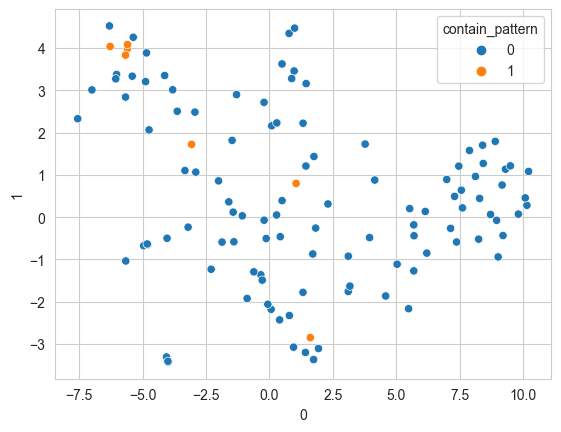

In [481]:
sns.scatterplot(data=result_df, x=0, y=1, hue='contain_pattern')

In [482]:
result_df[result_df.contain_pattern == 1]

,0,1,contain_pattern
0,-5.598927,3.982040,1
1,-6.281128,4.033267,1
2,-5.595543,4.078765,1
3,-5.672855,3.828090,1
40,-3.067614,1.719880,1
67,1.054472,0.797386,1
82,1.615887,-2.846400,1


In [483]:
df.iloc[result_df[result_df.contain_pattern == 1].index.values]

,id,seq,target_seq,target_seq_short,target_seq_no_dash,contain_pattern,len
0,sp|P30044.4| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKGK_(376)_KGVLFGVPGAFT_(3)_PG...,NLAELFKGKKGVLFGVPGAFTPGCSKTHLPGFVEQAEALKA,1,41
3,sp|P99029.2| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKGK_(376)_KGVLFGVPGAFT_(3)_PG...,NLAELFKGKKGVLFGVPGAFTPGCSKTHLPGFVEQAGALKA,1,41
4,sp|Q9R063.1| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKDK_(376)_KGVLFGVPGAFT_(3)_PG...,NLAELFKDKKGVLFGVPGAFTPGCSKTHLPGFVEQAGALKA,1,41
5,sp|Q9BGI1.2| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKGK_(376)_KGVLFGLPGAFT_(3)_PG...,NLAELFKGKKGVLFGLPGAFTPGCSKTHLPGFVEQADALKA,1,41
45,sp|O94561.1| [completeness=complete] [organis...,----------------------------------------------...,ITAN------------------------------------------...,ITAN_(78)_K_(376)_GLVIFAYPKAST_(3)_PGCTKQ_(224...,ITANKGLVIFAYPKASTPGCTKQGCGFRDNYPKIQA,1,36
72,sp|P9WIE0.1| [completeness=complete] [organis...,----------------------------------------------...,YRG-------------------------------------------...,YRG_(79)_R_(376)_RVIVYFYPAAST_(3)_PGCTKQ_(224)...,YRGRRVIVYFYPAASTPGCTKQACDFRDNLGDFTT,1,35
91,sp|P9WID8.1| [completeness=complete] [organis...,----------------------------------------------...,LLSD------------------------------------------...,LLSD_(78)_G_(376)_PVVLFFYPAAMT_(3)_PGCTKE_(224...,LLSDGPVVLFFYPAAMTPGCTKEACHFRDLAKEFAE,1,36


In [484]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

pca = PCA(n_components=2)



In [485]:
data = pca.fit_transform(features)

In [486]:
data.shape

(117, 2)

In [487]:
model = KMeans(n_clusters = 6, init = "k-means++")

In [488]:
label = model.fit_predict(data)

C:\Users\denkl\AppData\Roaming\Python\Python39\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


In [489]:
result_df['label'] = label.astype(str)


<AxesSubplot: xlabel='0', ylabel='1'>

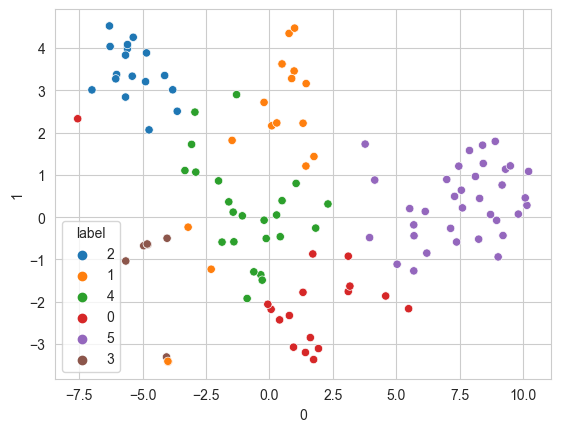

In [490]:
sns.scatterplot(data=result_df, x=0, y=1, hue='label')

In [491]:
result_df['peptide'] =  df.target_seq_no_dash.values

In [492]:
result_df[result_df['label'] == '1']

,0,1,contain_pattern,label,peptide
11,0.093297,2.159135,0,1,RWEDKTTEQIFGGKKVVLFSLPGAFTPTCSSNHLPRYEQLFEEFQA
15,1.328112,2.219784,0,1,RWEVRTTEDYFSGKRVVLFSLPGAFTPTCSTQQLPDFERLYDEFGK
22,-0.210131,2.712439,0,1,KTRDEWKGKKVVIVSIPGAYTPICHQQHIPPLVKRVDELKA
23,-1.470674,1.813917,0,1,QSHERWKGKKVVIVAVPGAFTPTCTANHVPPYVEKIQELKS
45,1.757993,1.433154,0,1,FQGQRVLVYFYPKAMTPGCTVQACGLRDNMDELKK
63,0.498253,3.620538,0,1,FKGKPVVLYFYPADETPGCTKQACAFRDSYEKYKK
64,0.975844,3.454024,0,1,FKGKPVVVYFYPADETPGCTKQACAFRDSYEKFKK
69,0.880140,3.275323,0,1,FKGRPVVVYFYPADETPGCTKQACAFRDSYEKFKK
73,1.450251,3.156579,0,1,LKGKKVILYFYPKDDTPGCTKEACGFRDVWSQLSK
74,0.292656,2.226680,0,1,ITENNRVVVFFVYPRASTPGCTRQACGFRDNYQELKK


In [493]:
result_df['len']= result_df.peptide.str.len().astype(str)

<AxesSubplot: xlabel='0', ylabel='1'>

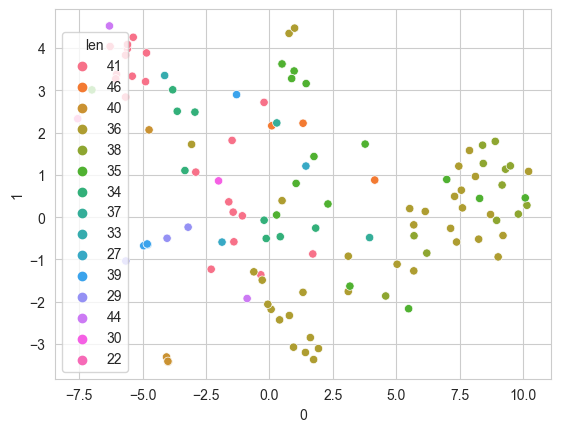

In [494]:
sns.scatterplot(data=result_df, x=0, y=1, hue='len')

In [495]:
c0_data = result_df[result_df.label == '0']
c1_data = result_df[result_df.label == '1']
c2_data = result_df[result_df.label == '2']
c3_data = result_df[result_df.label == '3']
c4_data = result_df[result_df.label == '4']
c5_data = result_df[result_df.label == '5']

In [496]:
c3_data.len.value_counts()

39    3
29    2
40    1
Name: len, dtype: int64

In [497]:
c3_data.len.value_counts().idxmax()

'39'

In [498]:
import logomaker
def make_logo(df, cluster_num=0):
    filtered = df[df.label == str(cluster_num)]
    idx_max = filtered.len.value_counts().idxmax()
    print("top length is ", idx_max)
    filtered = filtered[filtered['len'] == idx_max]
    print(str(cluster_num))
    matrix = logomaker.alignment_to_matrix(filtered['peptide'].values)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
     # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold')
    ww_logo.ax.set_title(f"Cluster {cluster_num}, len = {idx_max}, cnt = {len(filtered)}")

top length is  36
0


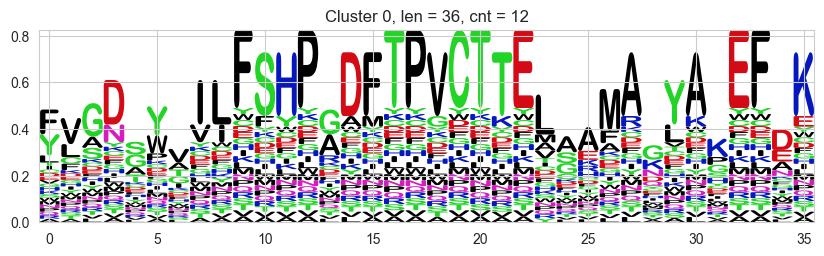

In [499]:
make_logo(result_df, 0)

top length is  35
1


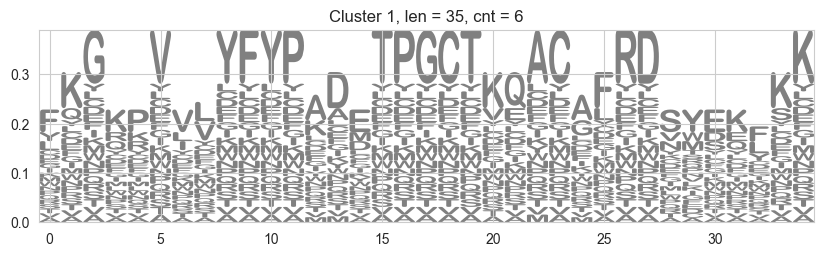

In [500]:
make_logo(result_df, 1)

top length is  41
2


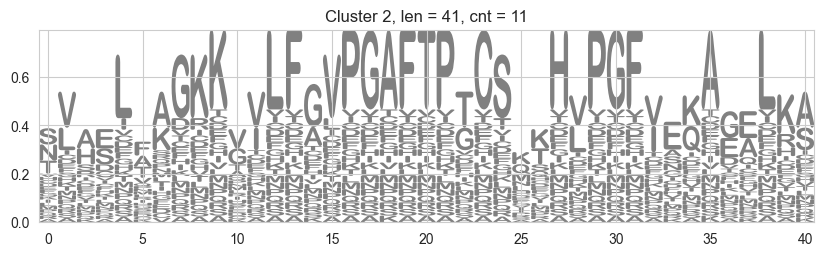

In [501]:
make_logo(result_df, 2)

top length is  39
3


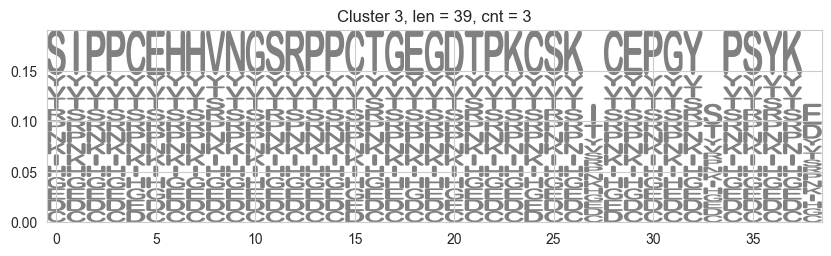

In [502]:
make_logo(result_df, 3)

top length is  41
4


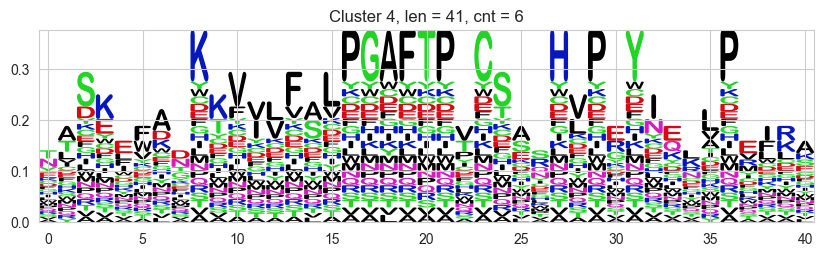

In [503]:
make_logo(result_df, 4)

top length is  36
5


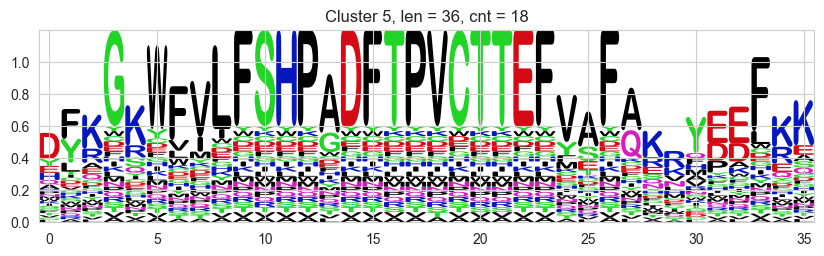

In [504]:
make_logo(result_df,  5)

In [505]:
df

,id,seq,target_seq,target_seq_short,target_seq_no_dash,contain_pattern,len
0,sp|P30044.4| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKGK_(376)_KGVLFGVPGAFT_(3)_PG...,NLAELFKGKKGVLFGVPGAFTPGCSKTHLPGFVEQAEALKA,1,41
3,sp|P99029.2| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKGK_(376)_KGVLFGVPGAFT_(3)_PG...,NLAELFKGKKGVLFGVPGAFTPGCSKTHLPGFVEQAGALKA,1,41
4,sp|Q9R063.1| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKDK_(376)_KGVLFGVPGAFT_(3)_PG...,NLAELFKDKKGVLFGVPGAFTPGCSKTHLPGFVEQAGALKA,1,41
5,sp|Q9BGI1.2| [completeness=complete] [organis...,----------------------------------------------...,NLA-----E-------------------------------------...,NLA_(5)_E_(69)_LFKGK_(376)_KGVLFGLPGAFT_(3)_PG...,NLAELFKGKKGVLFGLPGAFTPGCSKTHLPGFVEQADALKA,1,41
6,sp|Q69TY4.1| [completeness=complete] [organis...,----------------------------------------------...,TVR-----D-------------------------------------...,TVR_(5)_D_(69)_LTAGK_(376)_KVVLFAVPGAFT_(3)_PT...,TVRDLTAGKKVVLFAVPGAFTPTCTQKHVPGFVAKAGELRA,0,41
...,...,...,...,...,...,...,...
154,sp|P20155.2| [completeness=complete] [organis...,----------------------------------------------...,RLPGC-----------------------------------------...,RLPGC_(461)_PRHFN_(3)_PVCGSD_(224)_M_(18)_STYA...,RLPGCPRHFNPVCGSDMSTYANECTLCMKIREGGHNIKIIR,0,41
156,sp|A0A1L9U7P9.1| [completeness=complete] [org...,----------------------------------------------...,HMIPS-----------------------------------------...,HMIPS_(77)_M_(376)_YLHISRLPLSSS_(3)_GKLNRR_(22...,HMIPSMYLHISRLPLSSSGKLNRRQLREMVAQLPRQKLNE,0,40
166,sp|A0A319BQC1.1| [completeness=complete] [org...,----------------------------------------------...,YMIPS-----------------------------------------...,YMIPS_(77)_M_(376)_YLHISRLPLSAS_(3)_GKLNRR_(22...,YMIPSMYLHISRLPLSASGKLNRRHLREMVAELPRQRLNE,0,40
170,sp|Q9FLW9.1| [completeness=complete] [organis...,----------------------------------------------...,GMNVA-----------------------------------------...,GMNVA_(77)_R_(378)_MNMSHGDHAS_(6)_HKK_(224)_V_...,GMNVARMNMSHGDHASHKKVIDLVKEYNA,0,29


In [506]:
df.to_csv("test_tomas_result.csv", sep=';')

In [125]:
c3_data[c3_data['len'] == 41]['peptide']

Series([], Name: peptide, dtype: object)

In [126]:
c3_data

,0,1,contain_pattern,label,peptide,len
0,-4.484840,-8.345335,1,3,NLAELFKGKKGVLFGVPGAFTPGCSKTHLPGFVEQAEALKA,41
1,-4.806551,-9.227062,1,3,NLAELFKGKKGVLFGVPGAFTPGCSKTHLPGFVEQAGALKA,41
2,-4.485322,-8.957906,1,3,NLAELFKDKKGVLFGVPGAFTPGCSKTHLPGFVEQAGALKA,41
3,-4.378413,-8.703133,1,3,NLAELFKGKKGVLFGLPGAFTPGCSKTHLPGFVEQADALKA,41
4,-3.759199,-8.756032,0,3,TVAELTAGRKAVLFAVPGAFTPTCSQKHLPGFIEKAGELHA,41
5,-4.668779,-8.366778,0,3,TVSSLTAGKKTILFAVPGAFTPTCSQKHVPGFVSKAGELRS,41
6,-3.784705,-8.055193,0,3,SVHSLAAGKKVILFGVPGAFTPTCSMKHVPGFIEKAEELKS,41
7,-3.419693,-9.110956,0,3,SVHSIAAGKKVILFGVPGAFTPTCSMSHVPGFIGKAEELKS,41
8,-3.746555,-9.180757,0,3,SVHSLVAGKKVILFGVPGAFTPTCSLKHVPGFIEKAGELKS,41
9,-3.327372,-8.500899,0,3,SVHGLAAGKKVVLFGVPGAFTPTCSNQHVPGFINQAEQLKA,41


In [127]:
c3_data[c3_data['len'] == 41]

,0,1,contain_pattern,label,peptide,len
